# 01 – Erster Blick: DWD-Messungen Hamburg-Fuhlsbüttel

Stündliche Messwerte der DWD-Station 01975 ab 01.04.2024. Sie sind unsere „Wahrheit“, gegen die wir alle Modelle prüfen.
Wir nutzen Temperatur (`TT_TU`, °C) und Niederschlag (`R1`, mm pro Stunde). Die relative Luftfeuchte (`RF_TU`, %)
steht zusätzlich in der Datei, spielt im Projekt aber keine Rolle.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/full_datasets/dwd_01975_air_temperature_hourly.csv",
                 parse_dates=["time"]
)

df.head()

,time,STATIONS_ID,MESS_DATUM,QN_9,TT_TU,RF_TU,source
0,2024-04-01 00:00:00,1975,2024040100,3,7.9,91.0,historical
1,2024-04-01 01:00:00,1975,2024040101,3,7.6,93.0,historical
2,2024-04-01 02:00:00,1975,2024040102,3,7.5,93.0,historical
3,2024-04-01 03:00:00,1975,2024040103,3,7.1,94.0,historical
4,2024-04-01 04:00:00,1975,2024040104,3,6.8,95.0,historical


## Grundlegende Übersicht der Daten

In [2]:
print(f"Anzahl Zeilen: {len(df):,}")
print(f"Anzahl Spalten: {len(df.columns)}")

Anzahl Zeilen: 23,040
Anzahl Spalten: 7


In [3]:
print("Erster Datensatz:", df["time"].min())
print("Letzter Datensatz:", df["time"].max())

Erster Datensatz: 2024-04-01 00:00:00
Letzter Datensatz: 2026-11-16 23:00:00


In [4]:
print("Anzahl Stationen:", df["STATIONS_ID"].nunique())
print(df["STATIONS_ID"].unique())

Anzahl Stationen: 1
[1975]


## Fehlende Werte

In [5]:
missing = df.isna().sum()

missing_df = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": 100 * missing / len(df)
})

display(missing_df)

,missing_count,missing_percent
time,0,0.000000
STATIONS_ID,0,0.000000
MESS_DATUM,0,0.000000
QN_9,0,0.000000
TT_TU,153,0.664062
RF_TU,181,0.785590
source,0,0.000000


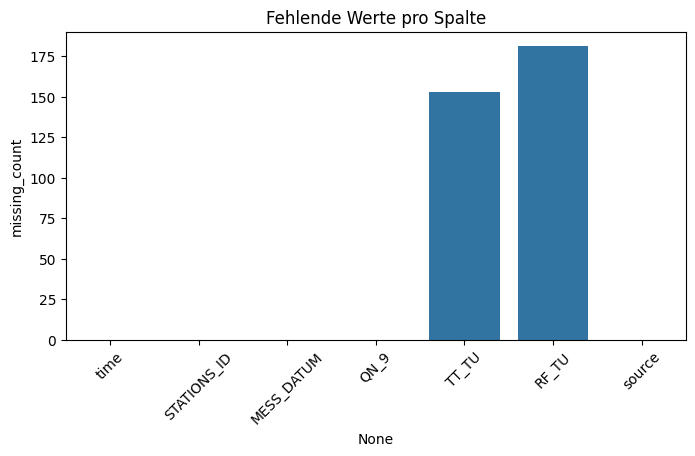

In [6]:
plt.figure(figsize=(8,4))
sns.barplot(
    x=missing_df.index,
    y=missing_df["missing_count"]
)
plt.xticks(rotation=45)
plt.title("Fehlende Werte pro Spalte")
plt.show()

## Sind alle Stunden und Tage vorhanden?

In [7]:
full_range = pd.date_range(
    start=df["time"].min(),
    end=df["time"].max(),
    freq="h"
)

missing_times = full_range.difference(df["time"])

print("Fehlende Stunden:", len(missing_times))

Fehlende Stunden: 0


In [8]:
df["date"] = df["time"].dt.date

daily_counts = df.groupby("date").size()

incomplete_days = daily_counts[daily_counts != 24]

print(f"Unvollständige Tage: {len(incomplete_days)}")
display(incomplete_days.head(20))

Unvollständige Tage: 0


Series([], dtype: int64)

## Temperaturverteilung

In [9]:
outliers = df[
    (df["TT_TU"] < -50) |
    (df["TT_TU"] > 50)
]

print(
    f"Verdächtige Datensätze: {len(outliers)}"
)

outliers.head()

Verdächtige Datensätze: 0


,time,STATIONS_ID,MESS_DATUM,QN_9,TT_TU,RF_TU,source,date


In [10]:
df["TT_TU"].describe()

count    22887.000000
mean        11.383786
std          7.323001
min        -13.400000
25%          6.000000
50%         11.800000
75%         16.700000
max         38.800000
Name: TT_TU, dtype: float64

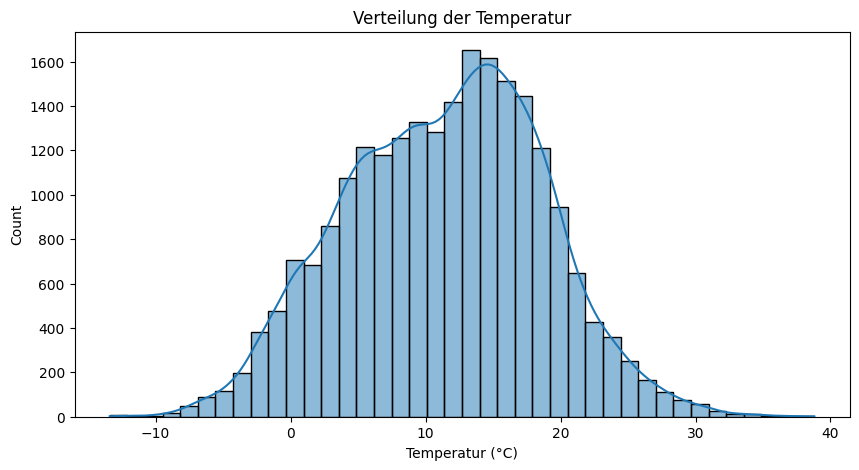

In [11]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["TT_TU"],
    bins=40,
    kde=True
)

plt.title("Verteilung der Temperatur")
plt.xlabel("Temperatur (°C)")
plt.show()

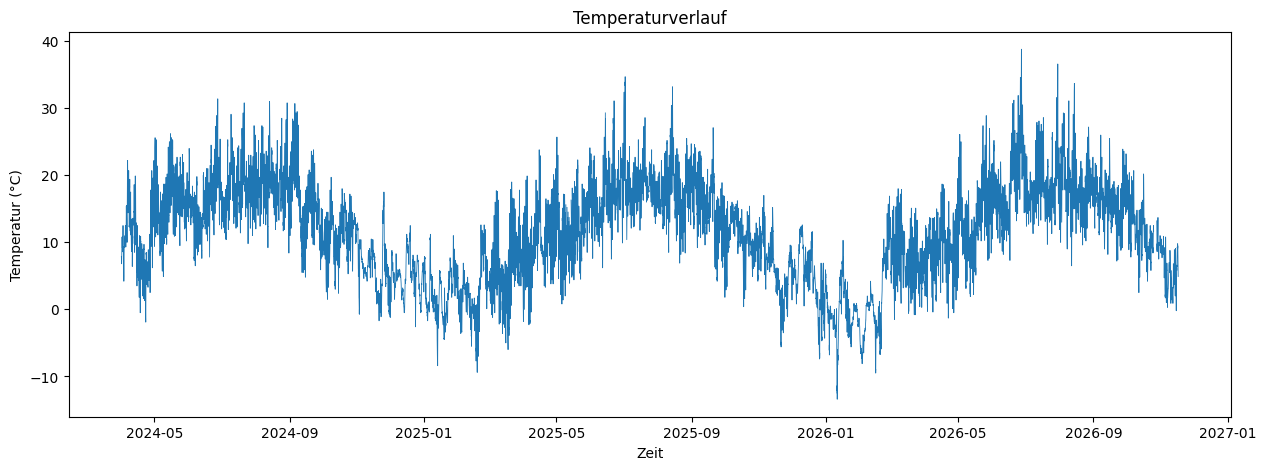

In [12]:
plt.figure(figsize=(15,5))

plt.plot(
    df["time"],
    df["TT_TU"],
    linewidth=0.6
)

plt.title("Temperaturverlauf")
plt.xlabel("Zeit")
plt.ylabel("Temperatur (°C)")
plt.show()

In [13]:
df["hour"] = df["time"].dt.hour

hourly_temp = (
    df.groupby("hour")["TT_TU"]
      .mean()
      .reset_index()
)

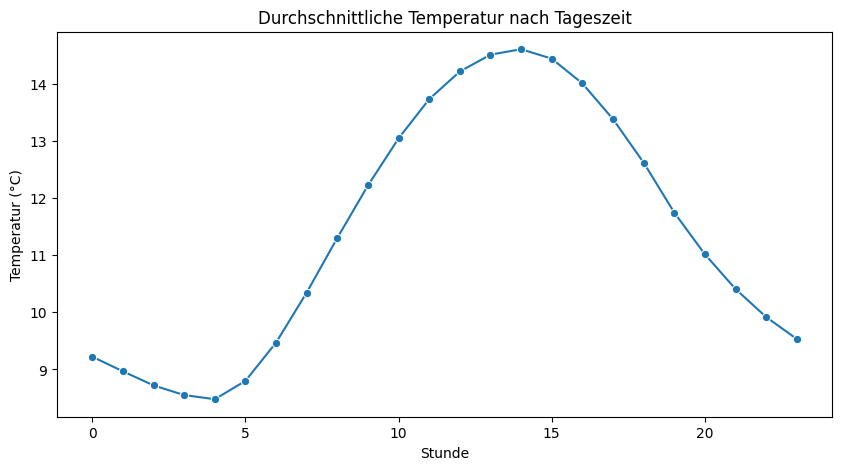

In [14]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=hourly_temp,
    x="hour",
    y="TT_TU",
    marker="o"
)

plt.title("Durchschnittliche Temperatur nach Tageszeit")
plt.xlabel("Stunde")
plt.ylabel("Temperatur (°C)")
plt.show()

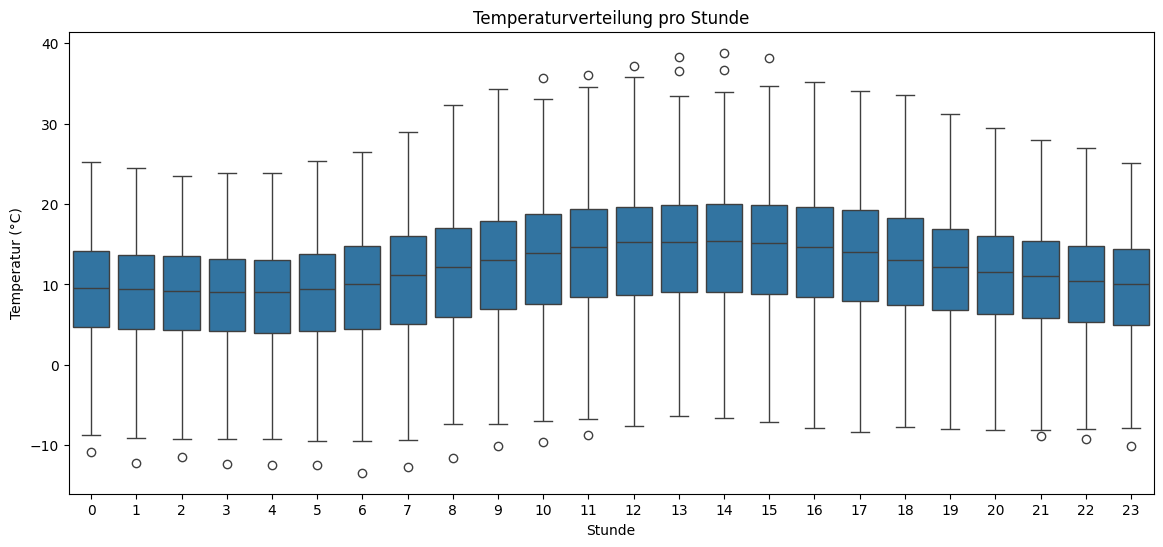

In [15]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df,
    x="hour",
    y="TT_TU"
)

plt.title("Temperaturverteilung pro Stunde")
plt.xlabel("Stunde")
plt.ylabel("Temperatur (°C)")
plt.show()

In [16]:
df["month"] = df["time"].dt.to_period("M")

monthly = (
    df.groupby("month")["TT_TU"]
      .mean()
      .reset_index()
)

monthly["month"] = monthly["month"].astype(str)


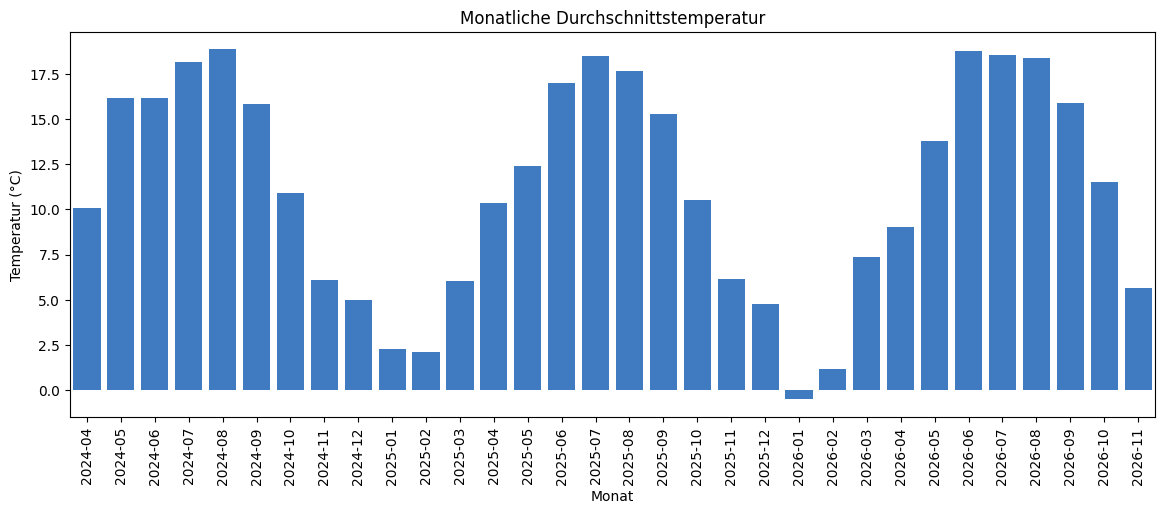

In [17]:
plt.figure(figsize=(14,5))

sns.barplot(
    data=monthly,
    x="month",
    y="TT_TU",
    color="#2a78d6"
)

plt.xticks(rotation=90)
plt.title("Monatliche Durchschnittstemperatur")
plt.xlabel("Monat")
plt.ylabel("Temperatur (°C)")
plt.show()

In [18]:
df["hour"] = df["time"].dt.hour
df["month"] = df["time"].dt.month

heatmap_data = (
    df.groupby(["month", "hour"])["TT_TU"]
      .mean()
      .unstack()
)

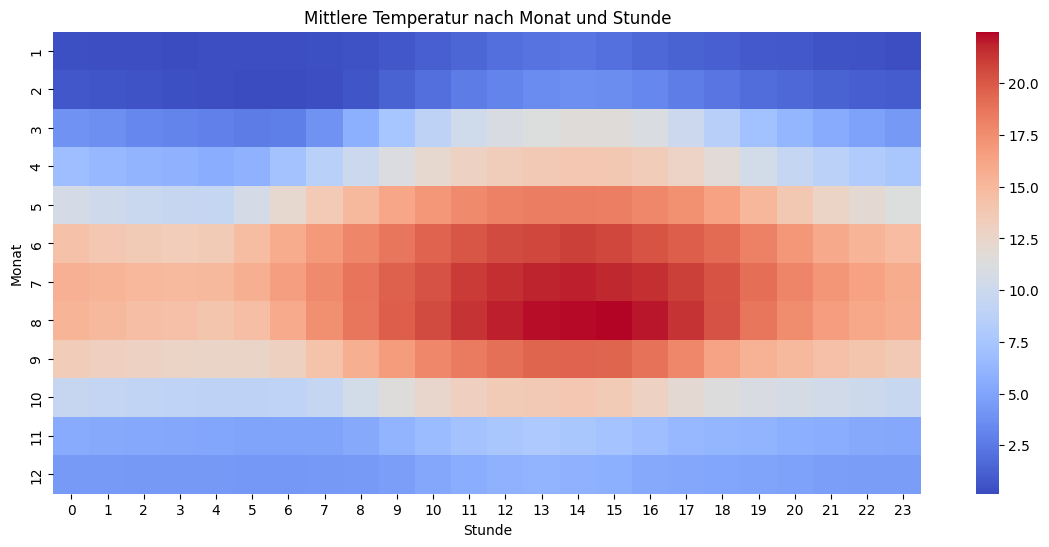

In [19]:
plt.figure(figsize=(14,6))

sns.heatmap(
    heatmap_data,
    cmap="coolwarm"
)

plt.title("Mittlere Temperatur nach Monat und Stunde")
plt.xlabel("Stunde")
plt.ylabel("Monat")

plt.show()

## Temperatur und Luftfeuchtigkeit

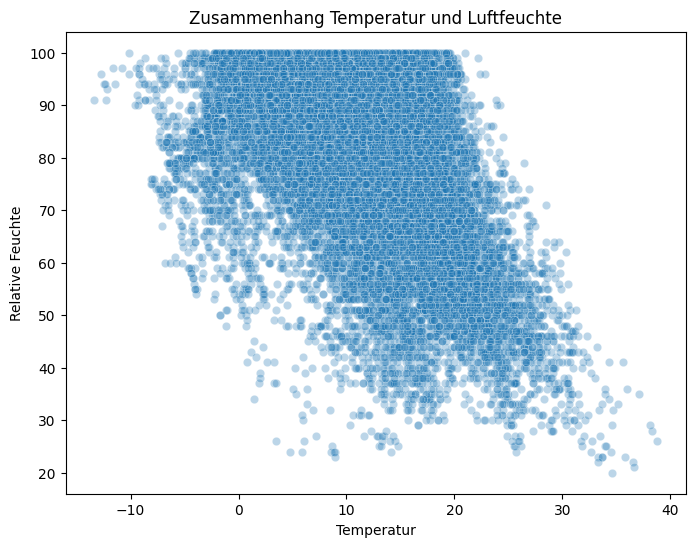

In [20]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="TT_TU",
    y="RF_TU",
    alpha=0.3
)

plt.xlabel("Temperatur")
plt.ylabel("Relative Feuchte")
plt.title("Zusammenhang Temperatur und Luftfeuchte")

plt.show()

In [21]:
print(
    df[["TT_TU", "RF_TU"]]
    .corr()
)

          TT_TU     RF_TU
TT_TU  1.000000 -0.518429
RF_TU -0.518429  1.000000


Temperatur und Luftfeuchte hängen negativ zusammen (r ≈ −0,52): Wenn es warm ist (mittags, Sommer), ist die relative
Luftfeuchte niedriger. Für das Projekt brauchen wir die Luftfeuchte aber nicht weiter.

## Niederschlag

Zweite DWD-Datei: stündliche Niederschlagssumme `R1` in mm. Der Wert zur Zeit t gilt für die Stunde **vor** t
(13:00 = Niederschlag von 12:00 bis 13:00). Mit dieser Zuordnung passen DWD und Modelle am besten zusammen (per Korrelation geprüft).

In [22]:
rain = pd.read_csv("../data/full_datasets/dwd_01975_rainfall_hourly.csv",
                   parse_dates=["time"]
)

rain.head()

,time,STATIONS_ID,MESS_DATUM,QN_8,R1,RS_IND,WRTR,source
0,2024-04-01 00:00:00,1975,2024040100,3,0.0,0.0,0.0,historical
1,2024-04-01 01:00:00,1975,2024040101,3,0.0,0.0,0.0,historical
2,2024-04-01 02:00:00,1975,2024040102,3,0.0,0.0,0.0,historical
3,2024-04-01 03:00:00,1975,2024040103,3,0.0,0.0,0.0,historical
4,2024-04-01 04:00:00,1975,2024040104,3,0.0,0.0,0.0,historical


In [23]:
missing_rain = rain[["R1", "RS_IND", "WRTR"]].isna().sum()

pd.DataFrame({
    "missing_count": missing_rain,
    "missing_percent": 100 * missing_rain / len(rain)
})

,missing_count,missing_percent
R1,124,0.538194
RS_IND,124,0.538194
WRTR,95,0.412326


In [24]:
wet_hours = (rain["R1"] > 0).mean()

print(f"Stunden mit Niederschlag: {wet_hours:.1%}")

rain["R1"].describe()

Stunden mit Niederschlag: 10.5%


count    22916.000000
mean         0.088488
std          0.548859
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         28.500000
Name: R1, dtype: float64

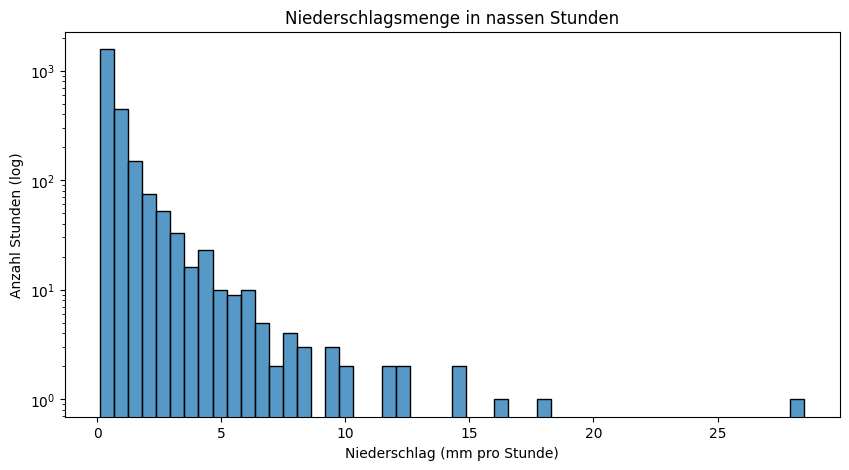

In [25]:
# Nur nasse Stunden, sonst dominiert die 0
wet = rain[rain["R1"] > 0]

plt.figure(figsize=(10,5))

sns.histplot(
    wet["R1"],
    bins=50
)

plt.yscale("log")
plt.title("Niederschlagsmenge in nassen Stunden")
plt.xlabel("Niederschlag (mm pro Stunde)")
plt.ylabel("Anzahl Stunden (log)")
plt.show()

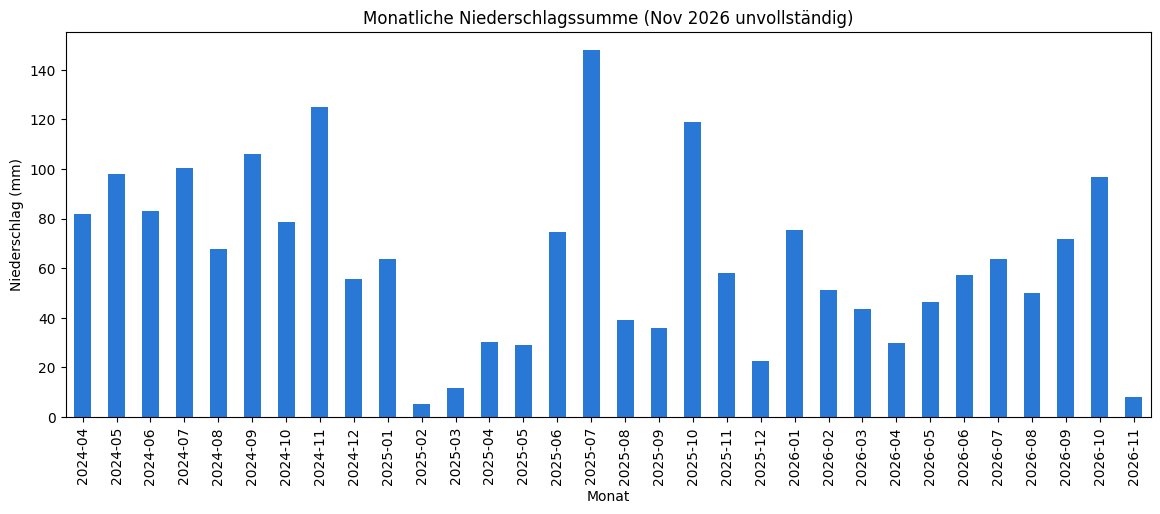

In [26]:
rain["month"] = rain["time"].dt.to_period("M")

monthly_rain = (
    rain.groupby("month")["R1"]
        .sum()
)

plt.figure(figsize=(14,5))
monthly_rain.plot(kind="bar", color="#2a78d6")
plt.title("Monatliche Niederschlagssumme (Nov 2026 unvollständig)")
plt.xlabel("Monat")
plt.ylabel("Niederschlag (mm)")
plt.show()

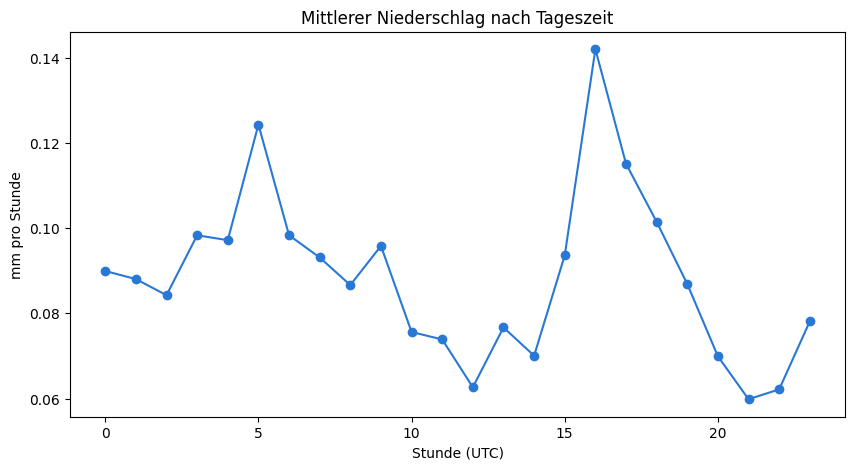

In [27]:
rain["hour"] = rain["time"].dt.hour

hourly_rain = (
    rain.groupby("hour")["R1"]
        .mean()
)

plt.figure(figsize=(10,5))
hourly_rain.plot(marker="o", color="#2a78d6")
plt.title("Mittlerer Niederschlag nach Tageszeit")
plt.xlabel("Stunde (UTC)")
plt.ylabel("mm pro Stunde")
plt.show()

In [28]:
# Die fünf stärksten Regenstunden
rain.nlargest(5, "R1")[["time", "R1"]]

,time,R1
2104,2024-06-27 16:00:00,28.5
2193,2024-07-01 09:00:00,18.2
20441,2026-07-31 17:00:00,16.1
1240,2024-05-22 16:00:00,14.8
2833,2024-07-28 01:00:00,14.4


## Qualitätsniveau

Der DWD prüft Daten in mehreren Stufen. Spalte `QN_9` (Temperatur) bzw. `QN_8` (Niederschlag):
1 = nur formal geprüft, 3 = automatisch geprüft und korrigiert.

In [29]:
df.groupby("QN_9")["time"].agg(["min", "max", "count"])

,min,max,count
QN_9,,,
1,2026-09-05,2026-11-16 23:00:00,1752
3,2024-04-01,2026-09-04 23:00:00,21288


## Erkenntnisse

- **Lückenlos:** 23.040 Stunden vom 01.04.2024 bis 16.11.2026, keine Stunde fehlt.
- **Fehlwerte:** Temperatur in 153 Stunden (0,7 %), Niederschlag in 124 Stunden (0,5 %). Diese Zeitpunkte lassen wir
  beim Vergleich mit den Modellen einfach weg.
- **Temperatur** zwischen −13,4 °C und 38,8 °C, keine unplausiblen Werte. Klarer Tagesgang (am wärmsten um 14 UTC)
  und Jahresgang.
- **Niederschlag:** Nur in etwa 10 % der Stunden regnet es. Die Verteilung ist sehr schief: fast immer 0, selten viel
  (Maximum 28,5 mm in einer Stunde am 27.06.2024). Für den Modellvergleich summieren wir auf 6-Stunden-Fenster.
- **Qualität:** Die Werte ab 05.09.2026 sind bisher nur formal geprüft (`QN` = 1). Der DWD kann sie noch korrigieren.